<font color ='Navy'><center> __EMship+(Advanced Design of Sustainable
Ships and Offshore Structures)__ </center></font>
<br> Offshore Structures & Digital Twin <br>  __Structural health monitoring for offshore structures__ <br> 
***
***
<font color='Navy' size=6><b><center>Working with experimental data</center></b></font> 
***
    
<div class="alert alert-block alert-info">
<center><b>Don't forget: It is important that you run each cell of the notebook. To do so select a cell (it will be highlighted) and press shift+enter on your keyboard or the play button in the menu above.</b></center></div> 

In [1]:
# let's import both numpy and matplotlib.pyplot 
# the "as" in the code bellow is to tell python that if we reference to the package using np and plt 
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib widget

We need also this function from the first part of the workshop.

In [ ]:
def calc_spectrum(signal, fs):
    """
    Calculates the FFT spectrum of signal sampled at the frequency fs
    
    signal - the signal of which you want to calculate the fft spectrum
    fs  - the sampling frequency in Hz
    
    returns:
    fft_freq - the frequency vector
    fft_value - the results of the 
    
    """
    from numpy.fft import fft, fftfreq, fftshift # We already imported the functions you'll need
    
    fft_values = fft(signal)/fs # 
    fft_freq = fftfreq(len(signal), 1/fs) # NOTE: 1/fs!!! 
    
    ## This additional step makes the plots look better, no need to worry about it :-)
    fft_values = fftshift(fft_values)
    fft_freq = fftshift(fft_freq)
        
    return fft_freq, fft_values

# 2. Offshore wind turbines
## Context

In today's session we will analyse the measurement data from an offshore wind turbine. The measurements that were shared are from two accelerometers installed in the nacelle of the wind turbine. The nacelle is the box at the top of the tower that houses the main drive shaft, gearbox and generator. We call the direction aligned with the wind direction the Fore-Aft direction (FA) and the direction cross-wind the sideways (SS) direction.

We will use the measurement to analyze the dynamic properties of the wind turbine and investigate it's susceptibility to different types of loading.  

<br><center><b>Figure 1: Two offshore wind turbines</b></center>
<img src="https://ilvo.vlaanderen.be/uploads/images/_900xAUTO_fit_center-center_none/RS2522_Thornton.jpg" width="600">


<div class="alert alert-block alert-info">
In the following exercices, we will use the same libraries as the one used previously. But we'll add a new package called `pandas`. `pandas` is a very useful package when it comes to importing and processing big datasets. It can handle all types of data and today we will use it to import measurement data. We'll use it later on in the session.
</div>

## Exercise 1: the rotor stop
To start the exercise we will first import some data from an actual offshore wind turbine in the North sea.
For this purpose we will use the package `pandas` and the `read_csv` command to read data from a csv file with the data stored in it. Once imported the data is stored in a so-called `Dataframe` (hence why we call it `df`). Using the `df.head()` command we show the first five lines of the Dataframe.

In [ ]:
import pandas as pd

df = pd.read_csv('offshore_wind_data_rotor_stop.csv', header=0)
df.head()


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">
<b> Assignment 1.1:</b>  Use the cell below to find key information about the measurement dataset. Define:

        - The sample frequency in Hz: `f_s`
        - The duration in s: `t_e`
        - The measurement unit of the acceleration: `unit_str`
 </div>
<div class="alert alert-block alert-info">
<center><b>Tips: to learn how to access/index pandas dataframe check this  
    <a href="https://www.datacamp.com/tutorial/pandas-tutorial-dataframe-python">link. </a> <br>
   To find the duration t_e, you either have to access the last row of the pandas dataframe or you have to compute the length of the dataframe
 </b></center></div>



In [ ]:
# add your code here

Some small checks

In [ ]:
assert f_s*t_e == len(df) # See if the total number of samples adds up

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 1.2:</b> use the `plt.plot` command to visualize the measurement data.
</div>


<div class="alert alert-block alert-info">
<center><b>Tips: Make your plot beautiful by adding: grid, legend, xlabel and ylabel. Google is your friend.  
 </b></center></div>

In [ ]:
plt.figure(figsize=(9,5))

# add your code here

plt.xlabel('Time [s]')
plt.ylabel('Acceleration [g]')
plt.legend()
plt.show()

In this dataset the turbine performs a so-called **rotor stop**, during a rotor stop the turbine shuts down and the wind load is released. In this video you can see an onshore wind turbine do a rotor stop:


In [ ]:
from IPython.display import YouTubeVideo

YouTubeVideo('_qVXkAWtH60', width=800, height=300)

In a way you could look at this rotor stop as an impulse response, so let us try to determine some of the wind turbine properties from it.
<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 1.3:</b> Can you isolate the data from the rotor stop in the FA and SS directions? Use `df.to_numpy` to extract data from a  dataframe into a numpy array (which is what we used in the previous sessions). Store your variable as `fa_rotor_stop` and `fss_rotor_stop`, also store the corresponding timevector (t=0s, on the rotor stop) in `t_rotor_stop`.
</div>

In [ ]:
# add your code here

# lets plot the signals during rotor stop
plt.figure(figsize=(9,5))
plt.plot(t_rotor_stop, fa_rotor_stop, label='FA during rotor stop')
plt.plot(tss_rotor_stop, fss_rotor_stop, label='SS during rotor stop')
plt.xlim([t_rotor_stop[0], t_rotor_stop[-1]])
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (g)')
plt.grid(which='both', linestyle=':')
plt.legend()
plt.show()

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 1.4:</b> Convert the impulse response data to the frequency domain using `calc_spectrum` and plot the resulting spectra. Use these spectra to estimate the first natural frequency of the structure. Utilize the `plt.semilogy()` function from matplotlib to achieve a logarithmic y-axis scale.

</div>

In [ ]:
plt.figure(figsize=(9,5))

# add your code here


plt.xlabel('Frequency (Hz)')
plt.ylabel('|Acceleration| (g)')
plt.grid(which='both', linestyle=':')
plt.legend()
plt.show()

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 1.4b:</b> What resonance frequency do you conclude for this structure? Set a variable `w_n` accordingly (best in rad/s).

</div>

In [ ]:
# add your code here

And let us check 

In [ ]:
###BEGIN HIDDEN TESTS
assert (abs(w_n- 1.85) <0.25)
###END HIDDEN TESTS

Finally we need to talk about the damping ratio. Do you already have a rough estimate of the damping value? Is it 0.1%, 1% or 10% damping. We can try to answer this by fitting the exponential decay of the impulse response to the data.

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.5:</b> Using the widget below can you match the damping ratio of the wind turbine? What value do you find, for the damping? Does that seem possible?

</div>

In [ ]:
import iplot.interactive_plot_2 as ip
ip.plot_interactive()

<details>
    <summary><b> Click to get the answer</b></summary>
    The damping matches at around 0.24%. That is realistic for a fully steel structure.
</details> 

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 1.5b:</b> Just for the record can you store your damping value (%) in `damping_owt`?

</div>

In [ ]:
# add your code here

Let us verify you provided an answer:

In [ ]:
assert damping_owt

### BEGIN HIDDEN TESTS
assert (damping_owt>0.2) and (damping_owt<0.3)
### END HIDDEN TESTS

## Exercise 2: the parked turbine

In the field of offshore wind energy the behaviour of a parked turbine (i.e. when it is not producing power) is almost equally important as the behaviour during operating conditions. At some sites the fatigue life is actually determined by the amount of time a turbine spends in parked conditions. A statement like "10% of downtime accounts for 90% of the fatigue life" is not uncommon.

In this exercise we will go to a **different wind farm**, and study the behaviour of a turbine that is parked. This time we will have 6 measurement signals, recorded at three different heights of the turbine. In offshore wind turbines the height is often related to a reference called LAT or Lowest Astronomical Tide, the lowest occuring tidal level. So a sensor labeled LAT015 is installed 15 meters above this reference level, and a sensor labeled LAT097 is installed 97m above this reference level. 

<img src="./Images/OWT_sensors.jpg" height=400 />

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.1:</b> Can you use pandas to import the measurement data that is stored in the file `offshore_wind_turbine_parked.csv`? Store the import in the variable `df`.

</div>

In [ ]:
# add your code here

Let us check your import

In [ ]:
assert len(df.columns) == 7, f'Did you import the new data? Your import  has {len(df.columns)} columns, we were expecting 7'

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.2:</b> Use the cell below to find key information about the measurement dataset. Define:

        - The sample frequency in Hz: `f_s`
        - The duration in s: `t_e`
        - The measurement unit of the acceleration: `unit_str`
</div>

In [ ]:
# add your code here

Some small checks

In [ ]:
assert f_s*t_e == len(df), f'Something does not add up, the data contains {len(df)} samples, yet t_e*f_s={t_e}*{f_s}={t_e*f_s}' # See if the total number of samples adds up

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.3:</b> use the `plt.plot` command to visualize the measurement data. Can you make sure to plot all 6 measurement signals?
</div>

In [ ]:
plt.figure(figsize=(9,5))

# add your code here

plt.xlabel('Time [s]')
plt.ylabel(f'Acceleration [{unit_str}]')
plt.legend()
plt.show()

This timeseries is a bit harder to interpret than that of the previous turbine. Perhaps transforming it into the frequency domain is more helpful in interpreting the results....

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.4:</b> Convert the measurement data to the frequency domain using `calc_spectrum` and plot the resulting amplitude spectra. Use these spectra to estimate the first natural frequency of the structure. Zoom in on the range between 0 and 2 Hz.

</div>

In [ ]:
plt.figure(figsize=(9,5))

# add your code here

plt.xlabel('Frequency (Hz)')
plt.ylabel('|Acceleration| (g)')
plt.grid(which='both', linestyle=':')
plt.xlim(0, 2)
plt.show()


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.5:</b> Try to answer following questions below. 

- How many modes can you spot between 0 and 2Hz?
- At which frequencies are they located? 
- Do you observe differences between the different sensor levels? Can you spot all modes at every level?
- Which mode is dominating the spectrum, i.e. carries the most energy?

</div>

<details>
    <summary><b> Click to get the answer</b></summary>
    
- There are 3 notable modes visible in the spectrum. Potentially there are more hidden underneath the noise.

- The first is around 0.23Hz, the second at around 0.75Hz and the third at around 1.34Hz
- Depending on which mode you consider a different sensor has the highest energy. E.g. for the first mode the sensors that carry the most energy are the top (LAT097) sensors. Meanwhile for the mode at 1.34Hz the lower sensors (LAT069 and LAT015) carry more energy
- The spectrum is dominated by the first mode at 0.23Hz, it contains by far the most energy.  
</details> 

These measurements can also provide us some insight into the mode shapes. While we can't derive the modeshapes directly from the spectrum we can visualize the so-called Operational Deflection Shapes (ODS) from it. These show how the structure vibrates at a given frequency. In particular at (well-seperated) resonance frequencies, these will resemble the mode shapes.

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.6:</b> Use the widget below to visualize the ODS at various frequencies for the FA signals. Can you relate the observed ODS to expected structural modes of the system?

</div>

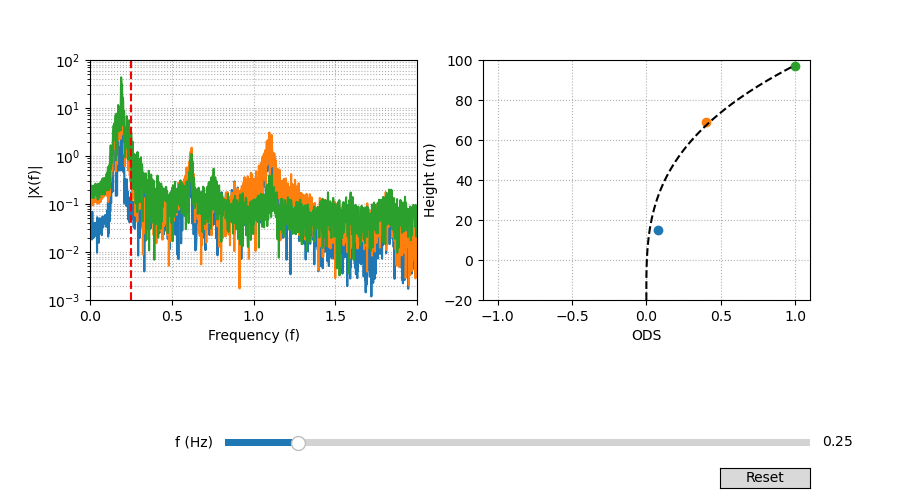

In [3]:
import iplot.interactive_plot_3 as ip
ip.plot_interactive()

Addtionally, I would like to share with you a very usefull tip when handling real-world data. In this sessions we talke about calculating spectra and windows. We did not speak of noise. The latter is always present and to some level will limit what we can do with measurements. When noise is too bad our signal will get flooded by noise and we won't be able to see what is going on. To resolve this we can work with averaging. A proper way of doing this is the so-called Welch's method.

Welch's method is a way to compute the **Power Spectral Density (PSD)** of a signal. Welch's method is available from `scipy.signal` as `welch`. `welch` does not only provide an implementation of Welch's method, it also simplifies the process of using a window.

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

<b> Assignment 2.7:</b> Import `welch` from `scipy.signal` and use it to calculate the PSD of the measurement data at LAT015 in the FA-direction contained in the dataframe `df`. Store the resulting frequency vectors as `f_psd` and the PSD itself as `psd`. Consider different settings of the windowing length and the window type. Also set the variable `psd_y_label` label to correct engineering units knowing the time domain signal is `g`. e.g. `psd_y_label='g'`
</div>


In [ ]:
# add your code here

Let us have a look at your results:

In [ ]:
# add your code here

<div class="alert alert-block alert-info">
<center><b>This concludes this part of the workshop, hope you learned a thing or two..</b></center></div> 